In [50]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import pandas as pd
import os
from sklearn.metrics import r2_score
from sentence_transformers import SentenceTransformer

# Load sentence embedding model (384 dim)
embedding_model = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2')

folder = os.listdir('data')
train_file = folder[1]
test_file = folder[0]
val_file = folder[2]

def load_data(file_path):
    with open(os.path.join('data', file_path), 'r') as f:
        data = pd.read_csv(f)
    return data

data_train = load_data(train_file)
data_test = load_data(test_file)
data_val = load_data(val_file)

data_train['Review'].head()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 502.69it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


0    nice hotel expensive parking got good deal sta...
1    ok nothing special charge diamond member hilto...
2    nice rooms not 4* experience hotel monaco seat...
3    unique, great stay, wonderful time hotel monac...
4    great stay great stay, went seahawk game aweso...
Name: Review, dtype: object

In [51]:
def vectorize_data(data, colone_name):
    # Encode reviews with sentence embeddings (dense numpy array 384-dim)
    return embedding_model.encode(data[colone_name].tolist())

# Vectorize all data (no fit/transform split needed)
data_train_vec = vectorize_data(data_train, 'Review')
data_train_vec_rating = torch.tensor(data_train['Rating'])

print('Train shape:', data_train_vec.shape)  # Should be (N, 384)
data_train_vec_rating

Train shape: (18491, 384)


tensor([4, 2, 3,  ..., 5, 1, 5])

In [52]:
# Optional: Unused BERT example (remove if not needed)
# from transformers import AutoTokenizer, AutoModelForMaskedLM
# model_id = "answerdotai/ModernBERT-base"
# tokenizer = AutoTokenizer.from_pretrained(model_id)
# model = AutoModelForMaskedLM.from_pretrained(model_id)
# ... (rest of BERT code if keeping)

In [53]:
class RegressionModel(nn.Module):
    def __init__(self, input_dim=384):  # Updated default for embeddings
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.7), #0.7
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.6),#0.6
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.8),#0.8
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.model(x)

row, dim = data_train_vec.shape
print(f'Input dim: {dim}')

data_val_vec = vectorize_data(data_val, 'Review')
data_val_rating_vec = torch.tensor(data_val['Rating'])

Input dim: 384


In [54]:
# Calcul des poids pour équilibrer le dataset
target_list = data_train['Rating'].values
class_sample_count = np.array([len(np.where(target_list == t)[0]) for t in np.unique(target_list)])
weight = 1. / class_sample_count
samples_weights = torch.from_numpy(np.array([weight[t - 1] for t in target_list])).double()

# Création du Sampler
sampler = torch.utils.data.WeightedRandomSampler(samples_weights, len(samples_weights))

In [55]:
# Train/val setup
batch_size = 256
n_samples = data_train_vec.shape[0]
all_train_error = []
epochs = 125
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# Val setup
n_samples_val = data_val_vec.shape[0]
all_val_error = []
batch_val_size = 256

# Model with embedding dim
model = RegressionModel(dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.00002)
loss_function = nn.HuberLoss()
model.train()

RegressionModel(
  (model): Sequential(
    (0): Linear(in_features=384, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.7, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.6, inplace=False)
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.8, inplace=False)
    (10): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [56]:
for epoch in range(epochs):
    total_loss = 0
    for start in range(0, n_samples, batch_size):
        end = start + batch_size
        
        # Batches (dense embeddings, no .todense())
        X_batch = torch.tensor(data_train_vec[start:end], dtype=torch.float32).to(device)
        Y_batch = torch.tensor(data_train_vec_rating[start:end], dtype=torch.float32).view(-1, 1).to(device)

        y_pred = model(X_batch)
        loss = loss_function(y_pred, Y_batch)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
    
    loss_error = total_loss / (n_samples / batch_size)
    all_train_error.append(loss_error)

    # Val
    model.eval()
    total_val_error = 0
    with torch.no_grad():
        for start in range(0, n_samples_val, batch_val_size):
            end = start + batch_val_size
            X_val_batch = torch.tensor(data_val_vec[start:end], dtype=torch.float32).to(device)
            Y_val_batch = torch.tensor(data_val_rating_vec[start:end], dtype=torch.float32).view(-1, 1).to(device)

            y_val_pred = model(X_val_batch)
            loss = loss_function(y_val_pred, Y_val_batch)
            total_val_error += loss.item()
        loss_val_error = total_val_error / (n_samples_val / batch_val_size)
        all_val_error.append(loss_val_error)
    
    print(f"Val error {loss_val_error:.4f}")
    print(f"Epoch {epoch+1}/{epochs}, Loss: {loss_error:.4f}")

print(f"Avg train loss: {sum(all_train_error)/epochs:.4f}")

/tmp/ipykernel_134266/551830463.py:8: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_batch = torch.tensor(data_train_vec_rating[start:end], dtype=torch.float32).view(-1, 1).to(device)
/tmp/ipykernel_134266/551830463.py:29: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  Y_val_batch = torch.tensor(data_val_rating_vec[start:end], dtype=torch.float32).view(-1, 1).to(device)


Val error 3.5667
Epoch 1/125, Loss: 3.3802
Val error 2.7928
Epoch 2/125, Loss: 3.1093
Val error 0.7632
Epoch 3/125, Loss: 1.6378
Val error 0.5185
Epoch 4/125, Loss: 0.5345
Val error 0.4624
Epoch 5/125, Loss: 0.4732
Val error 0.4210
Epoch 6/125, Loss: 0.4284
Val error 0.3900
Epoch 7/125, Loss: 0.3934
Val error 0.3672
Epoch 8/125, Loss: 0.3668
Val error 0.3505
Epoch 9/125, Loss: 0.3472
Val error 0.3383
Epoch 10/125, Loss: 0.3332
Val error 0.3291
Epoch 11/125, Loss: 0.3230
Val error 0.3217
Epoch 12/125, Loss: 0.3154
Val error 0.3155
Epoch 13/125, Loss: 0.3093
Val error 0.3101
Epoch 14/125, Loss: 0.3043
Val error 0.3054
Epoch 15/125, Loss: 0.2999
Val error 0.3012
Epoch 16/125, Loss: 0.2961
Val error 0.2973
Epoch 17/125, Loss: 0.2926
Val error 0.2938
Epoch 18/125, Loss: 0.2894
Val error 0.2906
Epoch 19/125, Loss: 0.2864
Val error 0.2877
Epoch 20/125, Loss: 0.2836
Val error 0.2850
Epoch 21/125, Loss: 0.2810
Val error 0.2824
Epoch 22/125, Loss: 0.2785
Val error 0.2800
Epoch 23/125, Loss: 0.27

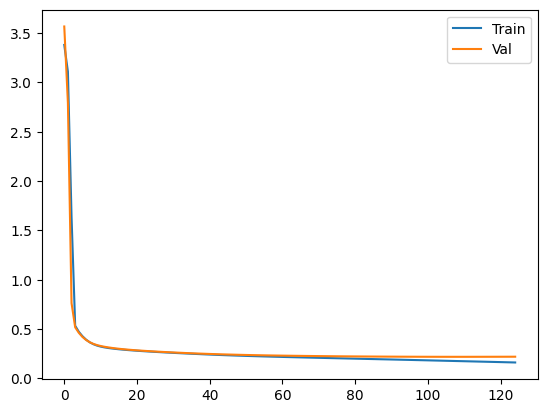

In [57]:
x = [i for i in range(epochs)]
y = all_train_error
z = all_val_error
plt.plot(x, y, label='Train')
plt.plot(x, z, label='Val')
plt.legend()
plt.show()

In [58]:
data_test_vec = vectorize_data(data_test, 'Review')
data_test_vec_rating = data_test['Rating']
y_test = torch.tensor(data_test_vec_rating)

batch_test_size = 32
n_samples_test = data_test_vec.shape[0]
model.eval()

RegressionModel(
  (model): Sequential(
    (0): Linear(in_features=384, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.7, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.6, inplace=False)
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.8, inplace=False)
    (10): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [59]:
total_test_loss = 0
with torch.no_grad():
    for start in range(0, n_samples_test, batch_test_size):
        end = start + batch_test_size
        x_batch_test = torch.tensor(data_test_vec[start:end], dtype=torch.float32).to(device)
        y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1).to(device)

        y_test_pred = model(x_batch_test)
        loss = loss_function(y_test_pred, y_batch_test)
        total_test_loss += loss.item()

print(f"Test MSE: {total_test_loss / (n_samples_test / batch_test_size):.4f}")

# Full R2
all_preds = []
all_true = []
with torch.no_grad():
    for start in range(0, n_samples_test, batch_test_size):
        end = start + batch_test_size
        x_batch_test = torch.tensor(data_test_vec[start:end], dtype=torch.float32).to(device)
        y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1)

        y_test_pred = model(x_batch_test)
        all_preds.extend(y_test_pred.cpu().numpy())
        all_true.extend(y_batch_test.numpy())

final_r2 = r2_score(all_true, all_preds)
print(f"Final R² on test: {final_r2:.4f}")

# Memory
if torch.cuda.is_available():
    print(f"GPU Mem allocated: {torch.cuda.memory_allocated() / 1024**2:.2f} MB")
    print(f"GPU Mem reserved: {torch.cuda.memory_reserved() / 1024**2:.2f} MB")

# Accuracy estimate (rounded preds)
correct = 0
total = len(all_true)
for pred, true in zip([round(p[0]) for p in all_preds], [t[0] for t in all_true]):
    if pred == true:
        correct += 1
success_rate = correct / total * 100
print(f"Success rate (rounded): {success_rate:.2f}%")

Test MSE: 0.2186
Final R² on test: 0.6626
GPU Mem allocated: 293.34 MB
GPU Mem reserved: 546.00 MB
Success rate (rounded): 59.50%


/tmp/ipykernel_134266/1382460104.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1).to(device)
/tmp/ipykernel_134266/1382460104.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_batch_test = torch.tensor(y_test[start:end], dtype=torch.float32).view(-1, 1)


In [60]:
#torch.save(model,'embed_model.pth')

In [61]:
(data_test.Rating==5).sum()/data_test.count()

Review    0.466
Rating    0.466
dtype: float64

(array([1310.,    0., 1630.,    0.,    0., 1982.,    0., 5465.,    0.,
        8104.]),
 array([1. , 1.4, 1.8, 2.2, 2.6, 3. , 3.4, 3.8, 4.2, 4.6, 5. ]),
 <BarContainer object of 10 artists>)

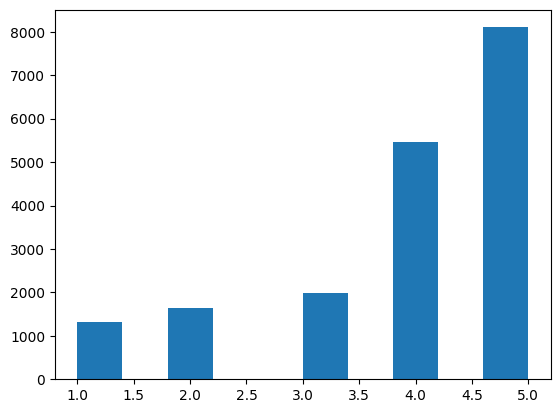

In [62]:
y=data_train["Rating"]
plt.hist(y)
